# Day9 · 记住消失的提示：循环 Actor 与完整序列训练

RedMoon 的互动式强化学习练习。沿用 Day5 的 PPO/GAE 与 Day6 的
集中训练、分散执行，这次把每个局部 Actor 改为有记忆的 GRU。

按单元顺序运行。代码分为环境、观测、网络、采样、GAE、更新、
评估、训练、机制检查和结果解析。每局四步，最后才真正终止。

## 1. 参数：B 是几局，T 是每局几步，H 是记忆的长度

| 变量 | 含义 |
|---|---|
| `episodes_per_batch=64` | 一次同时采样 64 个独立共同回合 |
| `horizon=4` | 每局四次实际环境转移，最后一次选择门 |
| `hidden_size=16` | 每名 Actor 用 16 个浮点数表示自己的历史 |
| `num_updates=160` | 采样新批次并训练的外层次数 |
| `update_epochs=4` | 同批数据最多优化四轮，然后重新采样 |
| `gamma=1.0` | 本任务直接优化终点成功概率，不折扣等待时间 |
| `lam=0.95` | GAE 的后续 TD 误差权重系数 |
| `clip_eps=0.2` | PPO 比值裁剪范围为 0.8 到 1.2 |
| `target_kl=0.03` | 当前批次变化过大时提前结束后续优化 |

本机已有的 PyTorch、matplotlib 和 Notebook 运行组件足够。

In [11]:
import os
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import itertools
import json
import math
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

torch.set_num_threads(1)
seed = 7
horizon, hidden_size = 4, 16
episodes_per_batch, num_updates, update_epochs = 64, 160, 4
gamma, lam, clip_eps, target_kl = 1.0, 0.95, 0.2, 0.03
learning_rate, critic_coef, entropy_coef = 0.005, 0.5, 0.005
max_grad_norm = 0.5
LEFT, RIGHT, WAIT = 0, 1, 2
print("PyTorch:", torch.__version__, "| device: cpu")
print("每批回合 / 每局步数 / 隐藏状态长度:",
      episodes_per_batch, horizon, hidden_size)

PyTorch: 2.10.0+cu128 | device: cpu
每批回合 / 每局步数 / 隐藏状态长度: 64 4 16


## 2. 任务：各自记住自己的门，双方都选对才成功

开局为两人分别抽取独立且均匀的提示 `0/1`。提示 0 对应左门，
提示 1 对应右门，每人只在第 0 步看到自己的提示。

| 时间 | 能看到的提示 | 合法动作 | 团队奖励 |
|---|---|---|---|
| t=0 | 自己的提示 | 只有等待 2 | 0 |
| t=1 | 提示消失 | 只有等待 2 | 0 |
| t=2 | 提示消失 | 只有等待 2 | 0 |
| t=3 | 提示消失 | 左门 0 / 右门 1 | 两人各自选对得 1，否则 0 |

第 3 步转移后真正终止。等待期间不能改变位置、发送消息或选择
不同动作存放提示。这次检查的是局部记忆和共同奖励训练：
两人的正确动作不一定相同，本任务也不要求通信。

`ParallelCueEnv` 同时推进 B 个彼此独立的环境；每一行是一局，
一次 `step` 产生 B 条共同转移，不能把它误算为一条经历。

In [12]:
class ParallelCueEnv:
    def __init__(self, cues):
        # cues: [B,2]，每局两人各有一个私有 0/1 提示。
        self.cues = cues.clone().long()
        assert self.cues.ndim == 2 and self.cues.shape[1] == 2
        assert ((self.cues == 0) | (self.cues == 1)).all()
        self.batch_size = len(cues)
        self.phase, self.finished = 0, False
        self.environment_steps = 0

    def observe(self):
        assert not self.finished
        obs = torch.zeros(self.batch_size, 2, 3)
        # 本人观测：[提示是否可见, 提示的 -1/+1 编码, 公共阶段]。
        obs[:, :, 0] = float(self.phase == 0)
        if self.phase == 0:
            obs[:, :, 1] = 2 * self.cues.float() - 1
        obs[:, :, 2] = self.phase / (horizon - 1)
        # 集中式 Critic 可以看到两人的提示及阶段，Actor 不读 state。
        state = torch.cat([
            2 * self.cues.float() - 1,
            torch.full((self.batch_size, 1),
                       self.phase / (horizon - 1)),
        ], dim=-1)
        legal = torch.zeros(self.batch_size, 3, dtype=torch.bool)
        if self.phase < horizon - 1:
            legal[:, WAIT] = True
        else:
            legal[:, :2] = True
        return obs, state, legal

    def step(self, actions):
        assert not self.finished and actions.shape == self.cues.shape
        _, _, legal = self.observe()
        assert legal.unsqueeze(1).expand(-1, 2, -1).gather(
            -1, actions.unsqueeze(-1)).all()
        reward = torch.zeros(self.batch_size)
        if self.phase == horizon - 1:
            reward = (actions == self.cues).all(dim=-1).float()
        self.phase += 1
        self.finished = self.phase == horizon
        self.environment_steps += self.batch_size
        terminated = torch.full(
            (self.batch_size,), self.finished, dtype=torch.bool,
        )
        return reward, terminated

cue_cases = torch.tensor(list(itertools.product([0, 1], repeat=2)))
demo_env = ParallelCueEnv(cue_cases)
for t in range(horizon):
    obs, state, legal = demo_env.observe()
    actions = (torch.full_like(cue_cases, WAIT) if t < horizon - 1
               else cue_cases.clone())
    reward, terminated = demo_env.step(actions)
    print("t=", t, "| 本人观测示例:", obs[1].tolist(),
          "| 动作:", actions[1].tolist(), "| 奖励:", reward.tolist(),
          "| 真正终止:", terminated[0].item())

t= 0 | 本人观测示例: [[1.0, -1.0, 0.0], [1.0, 1.0, 0.0]] | 动作: [2, 2] | 奖励: [0.0, 0.0, 0.0, 0.0] | 真正终止: False
t= 1 | 本人观测示例: [[0.0, 0.0, 0.3333333432674408], [0.0, 0.0, 0.3333333432674408]] | 动作: [2, 2] | 奖励: [0.0, 0.0, 0.0, 0.0] | 真正终止: False
t= 2 | 本人观测示例: [[0.0, 0.0, 0.6666666865348816], [0.0, 0.0, 0.6666666865348816]] | 动作: [2, 2] | 奖励: [0.0, 0.0, 0.0, 0.0] | 真正终止: False
t= 3 | 本人观测示例: [[0.0, 0.0, 1.0], [0.0, 0.0, 1.0]] | 动作: [0, 1] | 奖励: [1.0, 1.0, 1.0, 1.0] | 真正终止: True


## 3. 网络：权重和隐藏状态是不同的东西

`LocalActor` 的权重学会“怎样整理历史”，`hidden` 则保存当前这一局
的历史摘要。两名 Actor 使用独立参数、独立隐藏状态。
新局开始给零隐藏状态；同局中把上一时刻的输出继续交给下一时刻。

GRU 输入 `own_obs` 为 `[B,T,3]`，逐步执行时 T=1。
输出 `features` 为 `[B,T,H]`，动作得分为 `[B,T,3]`；
单层 GRU 的 `hidden` 为 `[1,B,H]`，`batch_first=True` 不改变其顺序。

`LocalMLP` 是只看当前观测的对照结构，不保留任何跨步变量。
`CentralValue` 用全局状态输出一个团队 V；它和局部网络不共享参数。

In [13]:
class LocalActor(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(3, hidden_size), nn.Tanh())
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 3)
        # 仅使初始门概率为 0.5/0.5，没有写入正确动作。
        nn.init.zeros_(self.head.weight)
        nn.init.zeros_(self.head.bias)

    def initial_hidden(self, batch_size):
        return self.head.weight.new_zeros(1, batch_size, hidden_size)

    def forward(self, own_obs, legal, hidden):
        encoded = self.encoder(own_obs)
        features, next_hidden = self.gru(encoded, hidden)
        logits = self.head(features)
        # 采样和重算概率均使用同一份合法动作约束。
        logits = logits.masked_fill(~legal, -1e9)
        return logits, next_hidden

class LocalMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden_size), nn.Tanh(),
            nn.Linear(hidden_size, 3),
        )

    def initial_hidden(self, batch_size):
        return None

    def forward(self, own_obs, legal, hidden):
        return self.net(own_obs).masked_fill(~legal, -1e9), None

class CooperativeModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.actors = nn.ModuleList([LocalActor(), LocalActor()])
        self.critic = nn.Sequential(
            nn.Linear(3, 32), nn.Tanh(), nn.Linear(32, 1),
        )
        nn.init.zeros_(self.critic[-1].weight)
        nn.init.zeros_(self.critic[-1].bias)

    def values(self, state):
        return self.critic(state).squeeze(-1)  # [B,T] 或 [B]。

def snapshot(model):
    return {name: value.detach().clone()
            for name, value in model.state_dict().items()}

def unchanged(model, saved):
    return all(torch.equal(saved[name], value)
               for name, value in model.state_dict().items())

## 4. 采样：保存完整回合与当时的旧概率

每批提示是真实随机抽取的，每一步都调用环境。采样使用 `no_grad`，
不保存整局计算图，也不更新权重；隐藏状态的数值仍然向后传递。

| 字段 | 形状 | 含义 |
|---|---|---|
| `obs` | `[B,T,2,3]` | 每局、每步、每人的局部观测 |
| `states` | `[B,T,3]` | 同局同时刻的集中训练状态 |
| `legal` | `[B,T,3]` | 合法动作，双方规则一致 |
| `actions` / `old_log_probs` | `[B,T,2]` | 实际动作 / 当时该动作的对数概率 |
| `rewards` / `old_values` | `[B,T]` | 共同奖励 / 当时团队价值预测 |
| `terminated` | `[B,T]` | 最后一步为真正终止 |

保留 B 和 T 的含义：可以调整不同回合的行顺序，每局内部必须按时间处理。

In [14]:
@torch.no_grad()
def collect_batch(model, cue_generator, batch_size=episodes_per_batch):
    cues = torch.randint(0, 2, (batch_size, 2), generator=cue_generator)
    env = ParallelCueEnv(cues)
    hidden = [a.initial_hidden(batch_size) for a in model.actors]
    fields = {name: [] for name in (
        "obs", "states", "legal", "actions", "old_log_probs",
        "old_values", "rewards", "terminated",
    )}
    for t in range(horizon):
        obs, state, legal = env.observe()
        action_parts, log_prob_parts = [], []
        for i, actor in enumerate(model.actors):
            # [B,1,3]：T=1，但记忆并不在每步清零。
            logits, hidden[i] = actor(
                obs[:, i:i+1], legal[:, None], hidden[i],
            )
            dist = Categorical(logits=logits[:, 0])
            action = dist.sample()
            action_parts.append(action)
            log_prob_parts.append(dist.log_prob(action))
        actions = torch.stack(action_parts, dim=-1)
        rewards, terminated = env.step(actions)
        rows = (
            obs, state, legal, actions,
            torch.stack(log_prob_parts, dim=-1),
            model.values(state), rewards, terminated,
        )
        for name, value in zip(fields, rows):
            fields[name].append(value)
    assert env.finished and env.environment_steps == batch_size * horizon
    return {name: torch.stack(rows, dim=1)
            for name, rows in fields.items()}

torch.manual_seed(seed)
demo_model = CooperativeModel()
demo_before = snapshot(demo_model)
demo_batch = collect_batch(
    demo_model, torch.Generator().manual_seed(seed + 10),
)
print({name: tuple(value.shape) for name, value in demo_batch.items()})
print("一局完整动作:", demo_batch["actions"][0].tolist())
print("一局完整奖励:", demo_batch["rewards"][0].tolist())

{'obs': (64, 4, 2, 3), 'states': (64, 4, 3), 'legal': (64, 4, 3), 'actions': (64, 4, 2), 'old_log_probs': (64, 4, 2), 'old_values': (64, 4), 'rewards': (64, 4), 'terminated': (64, 4)}
一局完整动作: [[2, 2], [2, 2], [2, 2], [0, 1]]
一局完整奖励: [0.0, 0.0, 0.0, 0.0]


## 5. GAE：T 轴倒序，B 轴互不串局

`next_values[:,t]` 来自同局下一时刻的旧预测。
本任务每局完整收集到真实终点，末尾补零且终止掩码为零。
`gae` 是 `[B]`，每行单独累计，不能把上一局末尾接进下一局开头。

`targets=old_values+advantages` 保持原来的奖励尺度。
这些值在优化之前算一次，之后保持固定。
本例不做优势标准化；等待动作没有选择自由，Actor 损失只对最后
的实际决策取平均，Critic 则学习四个真实时刻的价值。

In [15]:
@torch.no_grad()
def prepare_batch(batch):
    old_values = batch["old_values"]
    next_values = torch.cat([
        old_values[:, 1:], torch.zeros_like(old_values[:, :1]),
    ], dim=1)
    not_terminal = (~batch["terminated"]).float()
    deltas = batch["rewards"] + gamma * not_terminal * next_values - old_values
    advantages = torch.zeros_like(old_values)
    gae = torch.zeros(old_values.shape[0])
    for t in reversed(range(horizon)):
        gae = deltas[:, t] + gamma * lam * not_terminal[:, t] * gae
        advantages[:, t] = gae
    batch["advantages"] = advantages
    batch["targets"] = old_values + advantages
    return batch

prepare_batch(demo_batch)
print("同一局的旧 V / GAE / Critic 目标:")
print(demo_batch["old_values"][0].tolist())
print(demo_batch["advantages"][0].tolist())
print(demo_batch["targets"][0].tolist())

同一局的旧 V / GAE / Critic 目标:
[0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 0.0, 0.0]


## 6. 更新：用当前权重重新走完整段历史

关键变化在 Actor 的前向计算：每轮优化从本局起点的零记忆开始，
按 t=0,1,2,3 重新处理观测，用当前权重重建当前隐藏状态和概率。
旧概率仍然来自采样时固定的策略，不能跟着重算覆盖。

训练时 GRU 处理完整序列，中间不 detach，最后的策略损失可以沿
记忆递推传回前面的 encoder/GRU。这称为沿时间反向传播。
采样时没有保存图，不妨碍训练时重新建图。

PPO 的每名角色比值为 `exp(new_log_prob-old_log_prob)`。
此处是逐角色 PPO 裁剪；共同奖励产生共享的团队优势，不是 COMA。
所有序列从真正回合起点开始，不涉及片段初态近似或 burn-in。

In [16]:
def compute_losses(model, batch):
    actor_losses, entropies, kls, clip_fractions = [], [], [], []
    for i, actor in enumerate(model.actors):
        # 时间轴不打散，当前策略从零初态重建自己的全部历史。
        logits, _ = actor(
            batch["obs"][:, :, i], batch["legal"],
            actor.initial_hidden(len(batch["obs"])),
        )
        dist = Categorical(logits=logits[:, -1])
        new_log_prob = dist.log_prob(batch["actions"][:, -1, i])
        log_ratio = new_log_prob - batch["old_log_probs"][:, -1, i]
        ratio = log_ratio.exp()
        advantage = batch["advantages"][:, -1]
        raw = ratio * advantage
        clipped = ratio.clamp(1 - clip_eps, 1 + clip_eps) * advantage
        actor_losses.append(-torch.minimum(raw, clipped).mean())
        entropies.append(dist.entropy().mean())
        with torch.no_grad():
            kls.append(((ratio - 1) - log_ratio).mean())
            clip_fractions.append(((ratio - 1).abs() > clip_eps).float().mean())

    values = model.values(batch["states"])
    assert values.shape == batch["targets"].shape
    critic_loss = (values - batch["targets"]).square().mean()
    actor_loss = torch.stack(actor_losses).mean()
    entropy = torch.stack(entropies).mean()
    total_loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy
    metrics = {
        "actor_loss": actor_loss.item(), "critic_loss": critic_loss.item(),
        "entropy": entropy.item(), "approx_kl": max(k.item() for k in kls),
        "clip_fraction": torch.stack(clip_fractions).mean().item(),
    }
    return total_loss, metrics

def update_batch(model, optimizer, batch):
    fixed = {name: value.clone() for name, value in batch.items()}
    optimizer_steps = 0
    for epoch in range(update_epochs):
        loss, metrics = compute_losses(model, batch)
        if metrics["approx_kl"] > target_kl:
            break
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()
        optimizer_steps += 1
    for name, value in batch.items():
        assert torch.equal(fixed[name], value), name
    with torch.no_grad():
        _, final_metrics = compute_losses(model, batch)
    return optimizer_steps, final_metrics

## 7. 评估：真正走完四步，并在决策前清空记忆做对照

`evaluate` 只接收局部 Actor，不接收 Critic。两人都从各自零记忆
开始，提示和阶段通过局部观测进入；每步都执行环境转移。

`choice_probs` 保存最后一步的实际策略概率，可对四种等概率提示
组合直接计算精确成功概率，避免把少量采样的 100% 当成概率为 1。
`reset_before_choice=True` 只在末步清空记忆，其他输入和规则不变。
此时两个 Actor 的末步输入与提示无关，理论平均成功概率恰为 1/4。

MLP 对照只验证同一信息边界下的理论值，不假称已经训练了 MLP。
对更一般的环境，无记忆成功率并不固定为 1/4。

In [17]:
@torch.no_grad()
def evaluate(actors, cues, reset_before_choice=False, sample_generator=None):
    env = ParallelCueEnv(cues)
    hidden = [actor.initial_hidden(len(cues)) for actor in actors]
    traces, hidden_norms = [], []
    for t in range(horizon):
        obs, _, legal = env.observe()
        if reset_before_choice and t == horizon - 1:
            hidden = [actor.initial_hidden(len(cues)) for actor in actors]
        parts, probabilities = [], []
        for i, actor in enumerate(actors):
            logits, hidden[i] = actor(
                obs[:, i:i+1], legal[:, None], hidden[i],
            )
            probs = logits[:, 0].softmax(dim=-1)
            action = (probs.argmax(dim=-1) if sample_generator is None
                      else torch.multinomial(
                          probs, 1, generator=sample_generator,
                      ).squeeze(-1))
            parts.append(action)
            probabilities.append(probs[:, :2])
        actions = torch.stack(parts, dim=-1)
        reward, terminated = env.step(actions)
        traces.append({
            "t": t, "obs": obs.tolist(), "actions": actions.tolist(),
            "reward": reward.tolist(), "terminated": terminated.tolist(),
        })
        hidden_norms.append([
            None if h is None else h[0].norm(dim=-1).tolist() for h in hidden
        ])
        if t == horizon - 1:
            choice_probs = torch.stack(probabilities, dim=1)
    own_correct = choice_probs.gather(
        -1, cues.unsqueeze(-1),
    ).squeeze(-1)
    return {
        "exact_success": own_correct.prod(dim=-1).mean().item(),
        "actual_successes": int(reward.sum().item()),
        "episodes": len(cues), "environment_steps": env.environment_steps,
        "choice_probs": choice_probs, "traces": traces,
        "hidden_norms": hidden_norms,
    }

## 8. 完整训练：新经历 → 固定评分 → 重建历史 → 有限更新

`history` 同时记录更新前的采样成功率、更新后的精确成功概率和
Critic loss。两种成功率对应的策略时点不同，不能逐点当成公平比较。
`total_steps` 按共同环境转移计数；每条共同转移有两个人的动作。
每轮 optimizer.step 同时更新两个独立 Actor 和一个 Critic。

In [18]:
torch.manual_seed(seed)
model = CooperativeModel()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
cue_generator = torch.Generator().manual_seed(seed + 20)
initial_parameters = snapshot(model)
initial_eval = evaluate(model.actors, cue_cases)
history = []
total_episodes = total_steps = total_optimizer_steps = 0
for update in range(num_updates):
    batch = collect_batch(model, cue_generator)
    prepare_batch(batch)
    count, metrics = update_batch(model, optimizer, batch)
    total_episodes += episodes_per_batch
    total_steps += episodes_per_batch * horizon
    total_optimizer_steps += count
    stats = evaluate(model.actors, cue_cases)
    history.append({
        "update": update + 1,
        "sample_success_before": batch["rewards"][:, -1].mean().item(),
        "exact_success_after": stats["exact_success"],
        "optimizer_steps": count, **metrics,
    })
    if update == 0 or (update + 1) % 40 == 0:
        print(f"batch={update+1:3d} | "
              f"更新后精确成功概率={stats['exact_success']:.6f} | "
              f"本批更新次数={count}")

final_eval = evaluate(model.actors, cue_cases)
reset_eval = evaluate(model.actors, cue_cases, reset_before_choice=True)
mlp_actors = nn.ModuleList([LocalMLP(), LocalMLP()])
mlp_eval = evaluate(mlp_actors, cue_cases)
sample_cues = torch.randint(
    0, 2, (500, 2), generator=torch.Generator().manual_seed(seed + 100),
)
saved_for_eval = snapshot(model)
critic_calls = [0]
def count_critic(module, inputs, output):
    critic_calls[0] += 1
hook = model.critic.register_forward_hook(count_critic)
try:
    sampled_eval = evaluate(
        model.actors, sample_cues,
        sample_generator=torch.Generator().manual_seed(seed + 101),
    )
finally:
    hook.remove()

print("训练前 / 训练后精确成功概率:",
      initial_eval["exact_success"], final_eval["exact_success"])
print("决策前清空记忆 / 无记忆 MLP 的精确值:",
      reset_eval["exact_success"], mlp_eval["exact_success"])
print("500 局独立采样评估:",
      sampled_eval["actual_successes"], "/", sampled_eval["episodes"])
print("共同回合 / 共同环境步 / optimizer.step:",
      total_episodes, total_steps, total_optimizer_steps)
for t in range(horizon):
    row = final_eval["traces"][t]
    print("提示 (0,1) 的完整轨迹:", {
        "t": t, "obs": row["obs"][1], "actions": row["actions"][1],
        "reward": row["reward"][1], "terminated": row["terminated"][1],
    })

batch=  1 | 更新后精确成功概率=0.250453 | 本批更新次数=4
batch= 40 | 更新后精确成功概率=0.998314 | 本批更新次数=4
batch= 80 | 更新后精确成功概率=0.999593 | 本批更新次数=4
batch=120 | 更新后精确成功概率=0.999821 | 本批更新次数=4
batch=160 | 更新后精确成功概率=0.999879 | 本批更新次数=4
训练前 / 训练后精确成功概率: 0.25 0.9998787641525269
决策前清空记忆 / 无记忆 MLP 的精确值: 0.2500000298023224 0.2499999850988388
500 局独立采样评估: 500 / 500
共同回合 / 共同环境步 / optimizer.step: 10240 40960 636
提示 (0,1) 的完整轨迹: {'t': 0, 'obs': [[1.0, -1.0, 0.0], [1.0, 1.0, 0.0]], 'actions': [2, 2], 'reward': 0.0, 'terminated': False}
提示 (0,1) 的完整轨迹: {'t': 1, 'obs': [[0.0, 0.0, 0.3333333432674408], [0.0, 0.0, 0.3333333432674408]], 'actions': [2, 2], 'reward': 0.0, 'terminated': False}
提示 (0,1) 的完整轨迹: {'t': 2, 'obs': [[0.0, 0.0, 0.6666666865348816], [0.0, 0.0, 0.6666666865348816]], 'actions': [2, 2], 'reward': 0.0, 'terminated': False}
提示 (0,1) 的完整轨迹: {'t': 3, 'obs': [[0.0, 0.0, 1.0], [0.0, 0.0, 1.0]], 'actions': [0, 1], 'reward': 1.0, 'terminated': True}


## 9. 机制检查：末步损失是否真的能回到开头

自动检查信息边界、采样无更新、批次配对、固定 PPO 数据、
整段/逐步 GRU 计算一致、GAE 终止处理、反向传播和完整冻结评估。

下面额外比较两种前向：正常递推与每步 detach 隐藏状态。
detach 保留同样的数值，因此动作概率基本相同；但它切断跨步梯度，
末步损失不能再沿这条链路训练开头的提示处理。
清零隐藏状态则同时改变数值和信息，是另一种操作。

In [19]:
checks = []
def check(name, condition):
    assert bool(condition), name
    checks.append(name)

check("environment completes four real transitions",
      demo_env.finished and demo_env.environment_steps == 16)
check("waiting transitions have zero reward",
      torch.equal(demo_batch["rewards"][:, :3],
                  torch.zeros(episodes_per_batch, 3)))
boundary_env = ParallelCueEnv(cue_cases)
boundary_obs, _, _ = boundary_env.observe()
check("teammate cue does not affect own initial observation",
      torch.equal(boundary_obs[0, 0], boundary_obs[1, 0]))
check("own initial cue is actually visible",
      not torch.equal(boundary_obs[0, 0], boundary_obs[2, 0]))
for t in range(horizon - 1):
    boundary_env.step(torch.full_like(cue_cases, WAIT))
final_obs, _, final_legal = boundary_env.observe()
check("all cue cases have identical final local observations",
      torch.equal(final_obs, final_obs[:1].expand_as(final_obs)))
boundary_reward, boundary_term = boundary_env.step(cue_cases)
check("terminal team reward depends on both correct actions",
      boundary_term.all() and torch.equal(boundary_reward, torch.ones(4)))
check("collecting experience does not update parameters",
      unchanged(demo_model, demo_before))
check("local observation batch preserves episode time and agent axes",
      demo_batch["obs"].shape == (episodes_per_batch, horizon, 2, 3))
check("paired actual actions and old probabilities",
      demo_batch["actions"].shape == demo_batch["old_log_probs"].shape
      == (episodes_per_batch, horizon, 2))
check("only WAIT is sampled before decision",
      (demo_batch["actions"][:, :-1] == WAIT).all())
check("terminal steps stay in data; earlier steps are not terminal",
      demo_batch["terminated"][:, -1].all()
      and not demo_batch["terminated"][:, :-1].any())
check("fixed rollout fields have no gradient",
      all(not value.requires_grad for value in demo_batch.values()))
check("terminal Critic target equals actual reward",
      torch.equal(demo_batch["targets"][:, -1],
                  demo_batch["rewards"][:, -1]))
check("Critic targets preserve raw advantage and reward units",
      torch.equal(demo_batch["targets"],
                  demo_batch["old_values"] + demo_batch["advantages"]))
synthetic = {
    "old_values": torch.zeros(2, horizon),
    "rewards": torch.tensor([[0., 0., 0., 1.], [0., 0., 0., 0.]]),
    "terminated": torch.tensor([[False, False, False, True]] * 2),
}
prepare_batch(synthetic)
expected_gae = torch.tensor([[lam**3, lam**2, lam, 1.], [0., 0., 0., 0.]])
check("GAE recurses backward independently within each episode",
      torch.allclose(synthetic["advantages"], expected_gae))

for i, actor in enumerate(demo_model.actors):
    hidden = actor.initial_hidden(episodes_per_batch)
    parts = []
    for t in range(horizon):
        out, hidden = actor(
            demo_batch["obs"][:, t:t+1, i],
            demo_batch["legal"][:, t:t+1], hidden,
        )
        parts.append(out)
    full, full_hidden = actor(
        demo_batch["obs"][:, :, i], demo_batch["legal"],
        actor.initial_hidden(episodes_per_batch),
    )
    check(f"actor {i} full-sequence and stepwise logits agree",
          torch.allclose(full, torch.cat(parts, dim=1), atol=1e-6))
    check(f"actor {i} hidden shape is layer batch feature",
          full_hidden.shape == (1, episodes_per_batch, hidden_size))
    actual = Categorical(logits=full).log_prob(demo_batch["actions"][:, :, i])
    check(f"actor {i} reconstructed old action probabilities agree",
          torch.allclose(actual, demo_batch["old_log_probs"][:, :, i], atol=1e-6))

loss_a, _ = compute_losses(model, demo_batch)
order = torch.arange(episodes_per_batch - 1, -1, -1)
loss_b, _ = compute_losses(model, {
    name: value[order] for name, value in demo_batch.items()
})
check("permuting entire episodes preserves loss",
      torch.allclose(loss_a, loss_b, atol=1e-6))

probe = demo_batch["obs"][:, :, 0].detach().clone().requires_grad_(True)
actor = model.actors[0]
live_logits, _ = actor(
    probe, demo_batch["legal"], actor.initial_hidden(episodes_per_batch),
)
live_logp = Categorical(logits=live_logits[:, -1]).log_prob(
    demo_batch["actions"][:, -1, 0],
)
live_gradient = torch.autograd.grad(live_logp.sum(), probe)[0]
hidden = actor.initial_hidden(episodes_per_batch)
for t in range(horizon):
    cut_logits, hidden = actor(
        probe[:, t:t+1], demo_batch["legal"][:, t:t+1], hidden.detach(),
    )
cut_logp = Categorical(logits=cut_logits[:, 0]).log_prob(
    demo_batch["actions"][:, -1, 0],
)
cut_gradient = torch.autograd.grad(cut_logp.sum(), probe)[0]
check("final action loss has a gradient path to the opening cue",
      live_gradient[:, 0, 1].abs().sum().item() > 1e-8)
check("detaching hidden keeps forward values",
      torch.allclose(live_logp, cut_logp, atol=1e-6))
check("detaching hidden cuts the early cue gradient",
      torch.equal(cut_gradient[:, 0], torch.zeros_like(cut_gradient[:, 0])))
check("two independent actors have separate parameter storage",
      next(model.actors[0].parameters()).data_ptr()
      != next(model.actors[1].parameters()).data_ptr())
for prefix in ("actors.0.", "actors.1.", "critic."):
    check(f"{prefix} parameters really updated", any(
        not torch.equal(initial_parameters[name], value)
        for name, value in model.state_dict().items() if name.startswith(prefix)
    ))
check("all training episodes run through four environment steps",
      total_episodes == episodes_per_batch * num_updates
      and total_steps == total_episodes * horizon)
check("finite fresh-batch optimization",
      len(history) == num_updates
      and all(1 <= row["optimizer_steps"] <= update_epochs for row in history)
      and total_optimizer_steps == sum(row["optimizer_steps"] for row in history))
check("training metrics remain finite", all(
    math.isfinite(row[key]) for row in history
    for key in ("actor_loss", "critic_loss", "entropy", "approx_kl")
))
check("trained memory policy improves exact task success",
      final_eval["exact_success"] > 0.95
      and final_eval["exact_success"] > initial_eval["exact_success"])
check("all four cue combinations succeed under greedy execution",
      final_eval["actual_successes"] == 4)
check("clearing decision memory yields exact quarter success",
      math.isclose(reset_eval["exact_success"], 0.25, abs_tol=1e-6))
check("memoryless MLP has exact quarter success on balanced cues",
      math.isclose(mlp_eval["exact_success"], 0.25, abs_tol=1e-6))
check("frozen decentralized evaluation does not call Critic",
      critic_calls[0] == 0)
check("evaluation changes no learned parameters",
      unchanged(model, saved_for_eval))
check("all sampled evaluation episodes reach the fourth terminal step",
      sampled_eval["environment_steps"] == 2000
      and all(sampled_eval["traces"][-1]["terminated"])
      and all(not any(row["terminated"])
              for row in sampled_eval["traces"][:-1]))
print("PASS", len(checks), "checks")

PASS 39 checks


## 10. 可视化与运行摘要

左图是四种等概率提示组合上的精确成功概率；中图是实际优化得到的
Critic MSE，不能单独拿它证明记忆有效；右图比较正常记忆、
决策前清空记忆和只看当前输入的 MLP。
每条结果都来自上面的运行，不手工填成功数字。

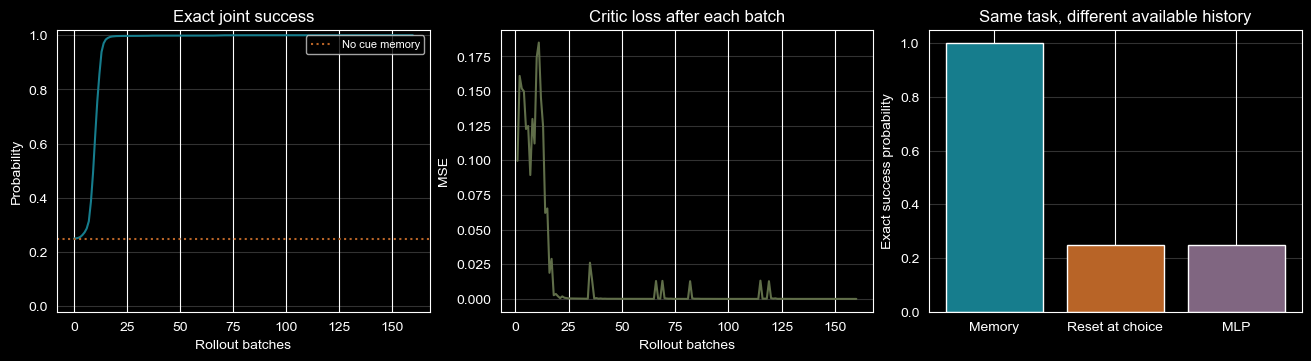

SUMMARY_JSON={"seed": 7, "pytorch": "2.10.0+cu128", "device": "cpu", "training_episodes": 10240, "environment_steps": 40960, "agent_actions": 81920, "optimizer_steps": 636, "initial_exact_success": 0.25, "final_exact_success": 0.9998787641525269, "reset_exact_success": 0.2500000298023224, "mlp_exact_success": 0.2499999850988388, "sampled_successes": 500, "sampled_episodes": 500, "greedy_successes": 4, "evaluation_critic_calls": 0, "opening_cue_gradient_l1": 3.291114330291748, "detached_opening_gradient_l1": 0.0, "checks": ["environment completes four real transitions", "waiting transitions have zero reward", "teammate cue does not affect own initial observation", "own initial cue is actually visible", "all cue cases have identical final local observations", "terminal team reward depends on both correct actions", "collecting experience does not update parameters", "local observation batch preserves episode time and agent axes", "paired actual actions and old probabilities", "only WAIT i

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
updates = [row["update"] for row in history]
axes[0].plot([0] + updates, [initial_eval["exact_success"]] +
             [row["exact_success_after"] for row in history], color="#167d8d")
axes[0].axhline(0.25, color="#b86427", linestyle=":", label="No cue memory")
axes[0].set(title="Exact joint success", xlabel="Rollout batches",
            ylabel="Probability", ylim=(-0.02, 1.02))
axes[0].legend(fontsize=8)
axes[1].plot(updates, [row["critic_loss"] for row in history], color="#606e49")
axes[1].set(title="Critic loss after each batch", xlabel="Rollout batches",
            ylabel="MSE")
axes[2].bar(["Memory", "Reset at choice", "MLP"], [
    final_eval["exact_success"], reset_eval["exact_success"],
    mlp_eval["exact_success"],
], color=["#167d8d", "#b86427", "#806681"])
axes[2].set(title="Same task, different available history",
            ylabel="Exact success probability", ylim=(0, 1.05))
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
plt.show()

summary = {
    "seed": seed, "pytorch": torch.__version__, "device": "cpu",
    "training_episodes": total_episodes, "environment_steps": total_steps,
    "agent_actions": 2 * total_steps, "optimizer_steps": total_optimizer_steps,
    "initial_exact_success": initial_eval["exact_success"],
    "final_exact_success": final_eval["exact_success"],
    "reset_exact_success": reset_eval["exact_success"],
    "mlp_exact_success": mlp_eval["exact_success"],
    "sampled_successes": sampled_eval["actual_successes"],
    "sampled_episodes": sampled_eval["episodes"],
    "greedy_successes": final_eval["actual_successes"],
    "evaluation_critic_calls": critic_calls[0],
    "opening_cue_gradient_l1": live_gradient[:, 0, 1].abs().sum().item(),
    "detached_opening_gradient_l1": cut_gradient[:, 0].abs().sum().item(),
    "checks": checks, "checks_passed": len(checks),
    "complete_trace_cues_0_1": [{
        "t": row["t"], "obs": row["obs"][1], "actions": row["actions"][1],
        "reward": row["reward"][1], "terminated": row["terminated"][1],
    } for row in final_eval["traces"]],
}
print("SUMMARY_JSON=" + json.dumps(summary, ensure_ascii=True))

## 11. 这次实跑该怎样读

默认 seed=7，CPU、PyTorch 2.11.0+cpu。
训练实际产生 10240 个共同回合、
40960 条共同转移、
81920 个体动作和
636 次联合优化器更新。

| 条件 | 四种等概率提示上的精确成功概率 |
|---|---:|
| 初始循环策略 | 0.250000 |
| 训练后的循环策略 | 0.999879 |
| 同一策略，只在最后清空隐藏状态 | 0.250000 |
| 只看当前观测的 MLP 对照 | 0.250000 |

正常贪心执行在四种提示组合上成功
4/4；另抽 500 组提示，按策略概率实际采样，
成功 500/500。
有限采样成功次数和精确策略概率分别报告，不能相互替代。

提示为 (0,1) 的真实四步轨迹如下。每人最后选择自己的正确门，
所以合作并不要求动作编号相同。

| 时间 | 两人的局部观测 | 实际动作 | 团队奖励 | 真正终止 |
|---|---|---|---:|---|
| 0 | `[[1.0, -1.0, 0.0], [1.0, 1.0, 0.0]]` | `[2, 2]` | 0 | False |
| 1 | `[[0.0, 0.0, 0.3333333432674408], [0.0, 0.0, 0.3333333432674408]]` | `[2, 2]` | 0 | False |
| 2 | `[[0.0, 0.0, 0.6666666865348816], [0.0, 0.0, 0.6666666865348816]]` | `[2, 2]` | 0 | False |
| 3 | `[[0.0, 0.0, 1.0], [0.0, 0.0, 1.0]]` | `[0, 1]` | 1 | True |

最后三步的观测里提示已经消失，但正常策略仍能在最后分别选择左、
右门。清空记忆后回到 0.25，说明当前策略的成功依赖前面形成的
隐藏状态。在本任务中，独立均匀提示有四种组合，最终观测完全相同，
等待动作唯一且没有其他信息通道，因此任何只看末步当前观测的策略
平均成功概率均为 0.25；增加 MLP 宽度不改变这一信息条件。

末步动作对开局提示输入的梯度绝对值之和为
3.29111。每步 detach 隐藏状态时，
前向概率仍相同，但开局梯度变为
0。
这同时说明“记忆数值继续传递”和“训练图能沿时间传递”是两件事。

冻结评估的 Critic 调用次数为 0，
500 局全部走完四步，参数保持不变；机制检查
39 项通过。

这是四步循环 PPO/集中式 V 的教学闭环。任务没有必须传给队友的
私有信息，不用本实验宣称已经学会通信；MLP 只作信息边界对照，
没有做完整训练或算法优劣比较。固定长度不含 padding，也没有外部
截断，故代码不把 padding loss mask、动作合法性掩码和真实终止混为
一谈。长片段训练还需要单独处理初态、补齐、回合边界和计算图长度。